<a href="https://colab.research.google.com/github/whoseei/Data-Bridge-Project-HITUNG-DISKON-TARIF-TOL-/blob/main/Regresi_Berganda_Musda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Latihan Regresi Linear Berganda (Data Panel)

Y (terikat) = KEMISKINAN

X (bebas) = bm_perlindungan_sosial, bm_lingkungan, PAD, PENGANGGURAN

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

## Baca data

In [19]:
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.strip()

# Pilih kota yang diinginkan (misal 3 kota)
daftar_kota = ['Kota Banda Aceh', 'Kota Medan', 'Kota Padang']
df = df[df['Kota'].isin(daftar_kota)].copy()
df


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,...,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,...,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,...,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,...,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,...,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52
5,Kota Banda Aceh,2019,92.60,29.52,51.04,142.44,61.59,51.67,93.28,175.40,...,264.69,169.35,252.67,128.65,149.56,15.94,8.40,0.31,68.96,6.05
6,Kota Banda Aceh,2020,97.36,58.70,34.77,107.83,68.51,69.25,90.38,171.14,...,237.09,200.45,287.09,178.02,174.29,18.31,6.31,0.32,77.83,6.83
7,Kota Banda Aceh,2021,102.50,83.44,49.04,165.62,93.72,67.32,72.74,135.43,...,159.80,195.43,72.83,285.17,216.85,14.55,5.20,0.40,82.69,5.95
8,Kota Banda Aceh,2022,81.18,72.27,35.37,119.55,74.24,66.84,111.08,208.16,...,202.64,150.37,90.36,61.95,53.19,14.50,9.10,0.46,64.66,4.39
9,Kota Banda Aceh,2023,115.08,97.74,70.87,173.29,82.99,91.80,106.69,271.82,...,90.09,134.52,290.19,138.06,267.89,17.91,3.05,0.40,70.44,5.08


## Cek struktur data panel

In [20]:
# data panel = banyak kota (cross section) x banyak tahun (time series)
print("jumlah kota :", df['Kota'].nunique())
print("jumlah tahun:", df['Tahun'].nunique())
print("jumlah baris:", len(df))

# kalau balanced, tiap kota punya jumlah tahun yang sama
df.groupby('Kota')['Tahun'].count().value_counts()

jumlah kota : 3
jumlah tahun: 11
jumlah baris: 33


,count
Tahun,
11,3


## Ambil variabel

In [21]:
kolom = ['Kota', 'Tahun', 'KEMISKINAN', 'bm_perlindungan_sosial', 'bm_lingkungan', 'PAD', 'PENGANGGURAN']
data = df[kolom].copy()

data.describe()

,Tahun,KEMISKINAN,bm_perlindungan_sosial,bm_lingkungan,PAD,PENGANGGURAN
count,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000
mean,2019.000000,12.521212,164.245455,176.724848,250.705758,6.283030
std,3.211308,4.633404,73.085976,69.834694,87.210025,2.120688
min,2014.000000,5.020000,53.190000,52.490000,119.840000,3.050000
25%,2016.000000,8.570000,97.970000,113.320000,179.240000,4.760000
50%,2019.000000,12.450000,161.680000,189.330000,245.120000,6.190000
75%,2022.000000,16.980000,225.320000,230.860000,280.390000,8.030000
max,2024.000000,19.890000,297.300000,269.800000,453.690000,9.890000


## Korelasi antar variabel

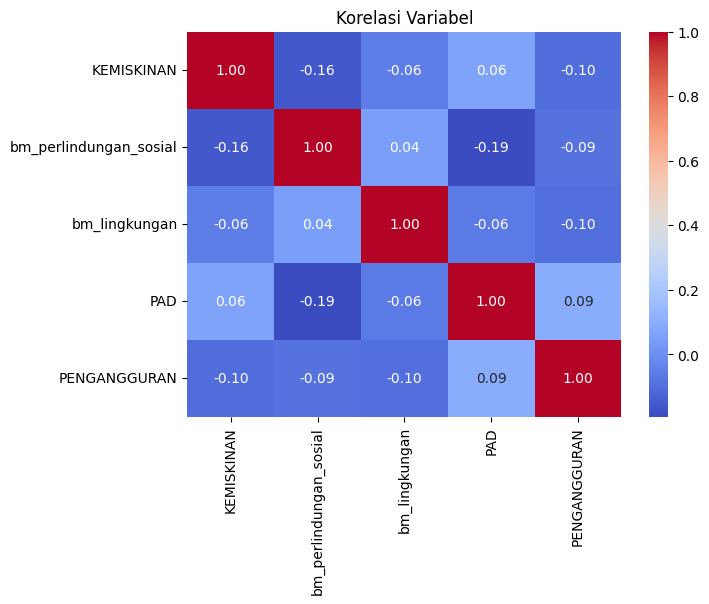

In [22]:
plt.figure(figsize=(7, 5))
sns.heatmap(data.drop(columns=['Kota', 'Tahun']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Variabel')
plt.show()

## Model 1: Regresi berganda biasa (Pooled OLS)

In [23]:
# rumus: Y ~ X1 + X2 + X3 + X4
model1 = smf.ols('KEMISKINAN ~ bm_perlindungan_sosial + bm_lingkungan + PAD + PENGANGGURAN', data=data).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                 -0.094
Method:                 Least Squares   F-statistic:                    0.3157
Date:                Mon, 12 Oct 2026   Prob (F-statistic):              0.865
Time:                        12:24:58   Log-Likelihood:                -96.188
No. Observations:                  33   AIC:                             202.4
Df Residuals:                      28   BIC:                             209.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 16

In [24]:
print("R-squared     :", round(model1.rsquared, 4))
print("Adj R-squared :", round(model1.rsquared_adj, 4))
print("Prob F        :", model1.f_pvalue)

# tabel ringkas koefisien dan p-value
hasil1 = pd.DataFrame({'koefisien': model1.params, 'p_value': model1.pvalues})
hasil1['signifikan'] = np.where(hasil1['p_value'] < 0.05, 'ya', 'tidak')
hasil1.round(4)

R-squared     : 0.0431
Adj R-squared : -0.0935
Prob F        : 0.8650592781652708


,koefisien,p_value,signifikan
Intercept,16.0701,0.0034,ya
bm_perlindungan_sosial,-0.0100,0.4105,tidak
bm_lingkungan,-0.0040,0.7513,tidak
PAD,0.0020,0.8428,tidak
PENGANGGURAN,-0.2724,0.5102,tidak


## Cek multikolinearitas (VIF)

In [25]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = data[['bm_perlindungan_sosial', 'bm_lingkungan', 'PAD', 'PENGANGGURAN']]
X = add_constant(X)

# VIF > 10 artinya ada multikolinearitas
vif = pd.DataFrame({'variabel': X.columns,
                    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif[vif['variabel'] != 'const'].round(3)

,variabel,VIF
1,bm_perlindungan_sosial,1.044
2,bm_lingkungan,1.013
3,PAD,1.048
4,PENGANGGURAN,1.022


## Model 2: Fixed Effect (tambah dummy Kota)

In [26]:
# C(Kota) = dummy tiap kota, jadi tiap kota punya intersep sendiri
model2 = smf.ols('KEMISKINAN ~ bm_perlindungan_sosial + bm_lingkungan + PAD + PENGANGGURAN + C(Kota)', data=data).fit()

# dummy kota ada banyak sekali, jadi yang ditampilkan hanya variabel X
hasil2 = pd.DataFrame({'koefisien': model2.params, 'p_value': model2.pvalues})
hasil2 = hasil2[~hasil2.index.str.startswith('C(')]

print("R-squared     :", round(model2.rsquared, 4))
print("Adj R-squared :", round(model2.rsquared_adj, 4))
hasil2.round(4)

R-squared     : 0.2685
Adj R-squared : 0.0997


,koefisien,p_value
Intercept,13.6279,0.0105
bm_perlindungan_sosial,-0.0087,0.4305
bm_lingkungan,-0.0014,0.9082
PAD,0.0294,0.0362
PENGANGGURAN,-0.5031,0.1975


## Bandingkan kedua model

In [27]:
perbandingan = pd.DataFrame({
    'Model': ['Pooled OLS', 'Fixed Effect'],
    'R-squared': [model1.rsquared, model2.rsquared],
    'Adj R-squared': [model1.rsquared_adj, model2.rsquared_adj],
    'AIC': [model1.aic, model2.aic]
})
perbandingan.round(4)

,Model,R-squared,Adj R-squared,AIC
0,Pooled OLS,0.0431,-0.0935,202.3762
1,Fixed Effect,0.2685,0.0997,197.5131


## Grafik

### 1. Nilai aktual vs prediksi

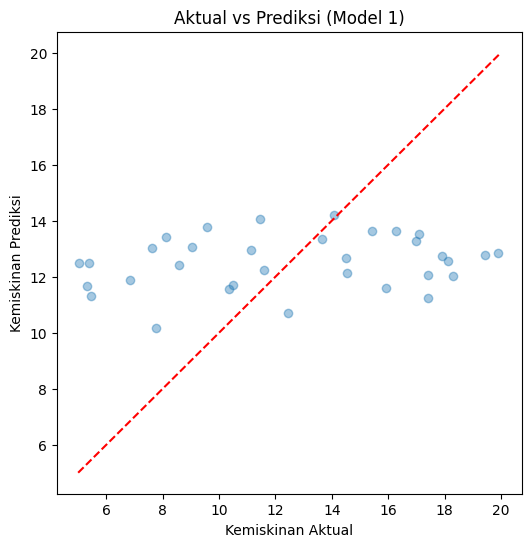

In [28]:
plt.figure(figsize=(6, 6))
plt.scatter(data['KEMISKINAN'], model1.fittedvalues, alpha=0.4)

# garis y = x (kalau pas, titik ada di garis ini)
plt.plot([5, 20], [5, 20], color='red', linestyle='--')

plt.title('Aktual vs Prediksi (Model 1)')
plt.xlabel('Kemiskinan Aktual')
plt.ylabel('Kemiskinan Prediksi')
plt.show()

### 2. Sebaran residual

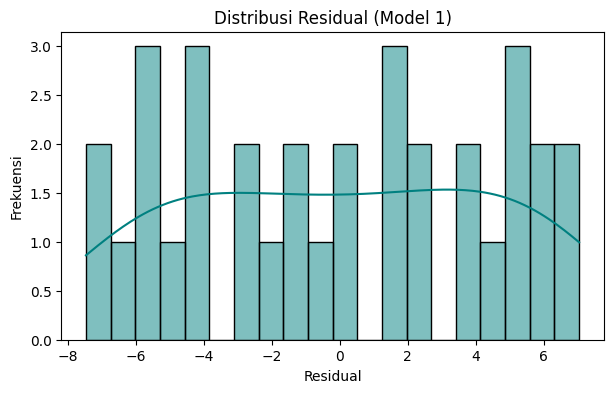

In [29]:
plt.figure(figsize=(7, 4))
sns.histplot(model1.resid, bins=20, kde=True, color='teal')

plt.title('Distribusi Residual (Model 1)')
plt.xlabel('Residual')
plt.ylabel('Frekuensi')
plt.show()

## Kesimpulan

1. Variabel Signifikan: Tidak ada variabel bebas (bm_perlindungan_sosial, bm_lingkungan, PAD, PENGANGGURAN) yang berpengaruh signifikan secara statistik terhadap kemiskinan pada taraf nyata 5% ($p > 0.05$).
2. Nilai R-squared: R-squared Pooled OLS sebesar 0.0431 (4.31%) dan Fixed Effect sebesar 0.2685 (26.85%), artinya kemampuan variabel independen dalam menjelaskan tingkat kemiskinan masih tergolong rendah dan sebagian besar dipengaruhi oleh faktor lain di luar model.
3. Uji Multikolinearitas (VIF): Aman. Seluruh nilai VIF berada di kisaran 1.013 hingga 1.048 (jauh di bawah 10), sehingga tidak ada masalah multikolinearitas.
4. Perbandingan Model: Berdasarkan nilai AIC, model Fixed Effect (AIC: 197.51) sedikit lebih baik dibanding Pooled OLS (AIC: 202.38) karena penambahan efek kota mampu menaikkan nilai R-squared menjadi 26.85%.